In [1]:
# ==========================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from IPython.display import display

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# ==========================================
# 2. CARGA DEL DATASET
# ==========================================

url_datos = "https://medata.app.medellin.gov.co/sites/default/files/distribution/1-011-08-000065/desercion_educativa.csv"

df = pd.read_csv(url_datos, encoding="utf-8")

print("Base de datos cargada correctamente")
print("Número de registros:", df.shape[0])
print("Número de columnas:", df.shape[1])

display(df.head())

Base de datos cargada correctamente
Número de registros: 1134
Número de columnas: 52


,año,codigo_dane,establecimiento_educativo,sector,comuna_establecimiento,sexo,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
0,2017,105001000001,inst educ jose maria velaz,oficial,2,hombres,0,0,0,2,...,14,17,0,0,0,0,0,0,0,0
1,2017,105001000001,inst educ jose maria velaz,oficial,2,mujeres,0,0,0,3,...,30,21,0,0,0,0,0,0,0,0
2,2017,105001000043,inst educ barrio santa cruz,oficial,2,hombres,0,0,1,4,...,20,23,0,0,3,21,57,41,40,0
3,2017,105001000043,inst educ barrio santa cruz,oficial,2,mujeres,0,0,1,1,...,44,19,0,0,13,10,31,51,28,0
4,2017,105001000094,col comfama - sede aranjuez,no oficial,4,hombres,1,2,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# ==========================================
# 3. EXPLORACIÓN DE LA BASE DE DATOS
# ==========================================

print("DIMENSIONES DEL DATASET")
print(df.shape)

print("\nTIPOS DE DATOS")
print(df.dtypes.value_counts())

print("\nINFORMACIÓN GENERAL")
df.info()

print("\nVALORES FALTANTES")
print(df.isnull().sum().sum())

print("\nREGISTROS DUPLICADOS")
print(df.duplicated().sum())

print("\nCOLUMNAS DEL DATASET")
print(df.columns.tolist())

DIMENSIONES DEL DATASET
(1134, 52)

TIPOS DE DATOS
int64    49
str       3
Name: count, dtype: int64

INFORMACIÓN GENERAL
<class 'pandas.DataFrame'>
RangeIndex: 1134 entries, 0 to 1133
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   año                         1134 non-null   int64
 1   codigo_dane                 1134 non-null   int64
 2   establecimiento_educativo   1134 non-null   str  
 3   sector                      1134 non-null   str  
 4   comuna_establecimiento      1134 non-null   int64
 5   sexo                        1134 non-null   str  
 6   desercion_grado_prejardin   1134 non-null   int64
 7   desercion_grado_jardin      1134 non-null   int64
 8   desercion_grado_transicion  1134 non-null   int64
 9   desercion_grado_1           1134 non-null   int64
 10  desercion_grado_2           1134 non-null   int64
 11  desercion_grado_3           1134 non-null   int64
 12  deserci

In [4]:
# ==========================================
# 4. SELECCIÓN DE VARIABLES PARA PCA
# ==========================================

# Seleccionar variables de deserción y matrícula
columnas_pca = [
    columna for columna in df.columns
    if columna.startswith(("desercion_", "matricula_"))
]

# Crear el conjunto de datos para PCA
df_pca = df[columnas_pca].copy()

print("VARIABLES SELECCIONADAS PARA PCA")
print("Cantidad de variables:", len(columnas_pca))
print("Cantidad de registros:", df_pca.shape[0])

print("\nCOLUMNAS SELECCIONADAS:")
print(columnas_pca)

print("\nPRIMEROS REGISTROS:")
display(df_pca.head())

VARIABLES SELECCIONADAS PARA PCA
Cantidad de variables: 46
Cantidad de registros: 1134

COLUMNAS SELECCIONADAS:
['desercion_grado_prejardin', 'desercion_grado_jardin', 'desercion_grado_transicion', 'desercion_grado_1', 'desercion_grado_2', 'desercion_grado_3', 'desercion_grado_4', 'desercion_grado_5', 'desercion_escuela_nueva', 'desercion_grado_6', 'desercion_grado_7', 'desercion_grado_8', 'desercion_grado_9', 'desercion_grado_10', 'desercion_grado_11', 'desercion_grado_12', 'desercion_grado_13', 'desercion_grado_clei1', 'desercion_grado_clei2', 'desercion_grado_clei3', 'desercion_grado_clei4', 'desercion_grado_clei5', 'desercion_grado_clei6', 'matricula_grado_pj', 'matricula_grado_jd', 'matricula_grado_transicion', 'matricula_grado_1', 'matricula_grado_2', 'matricula_grado_3', 'matricula_grado_4', 'matricula_grado_5', 'matricula_escuela_nueva', 'matricula_grado_6', 'matricula_grado_7', 'matricula_grado_8', 'matricula_grado_9', 'matricula_grado_10', 'matricula_grado_11', 'matricula_gra

,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,desercion_grado_2,desercion_grado_3,desercion_grado_4,desercion_grado_5,desercion_escuela_nueva,desercion_grado_6,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
0,0,0,0,2,1,0,0,0,0,0,...,14,17,0,0,0,0,0,0,0,0
1,0,0,0,3,1,1,0,0,0,2,...,30,21,0,0,0,0,0,0,0,0
2,0,0,1,4,4,1,7,2,0,16,...,20,23,0,0,3,21,57,41,40,0
3,0,0,1,1,0,1,1,4,0,9,...,44,19,0,0,13,10,31,51,28,0
4,1,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# ==========================================
# 5. ANÁLISIS DE VARIABILIDAD
# ==========================================

# Calcular la varianza de cada variable
varianzas = df_pca.var()

# Identificar variables sin variabilidad
variables_constantes = varianzas[varianzas == 0]

print("ANÁLISIS DE VARIANZA")
print("Total de variables:", len(varianzas))
print("Variables con variabilidad:", (varianzas > 0).sum())
print("Variables sin variabilidad:", len(variables_constantes))

if len(variables_constantes) > 0:
    print("\nVARIABLES CONSTANTES:")
    display(variables_constantes)
else:
    print("\nTodas las variables presentan variabilidad.")

print("\nRESUMEN ESTADÍSTICO:")
display(df_pca.describe().T)

ANÁLISIS DE VARIANZA
Total de variables: 46
Variables con variabilidad: 44
Variables sin variabilidad: 2

VARIABLES CONSTANTES:


desercion_grado_12    0.0
desercion_grado_13    0.0
dtype: float64


RESUMEN ESTADÍSTICO:


,count,mean,std,min,25%,50%,75%,max
desercion_grado_prejardin,1134.0,0.082011,0.455789,0.0,0.0,0.0,0.00,7.0
desercion_grado_jardin,1134.0,0.072310,0.389707,0.0,0.0,0.0,0.00,4.0
desercion_grado_transicion,1134.0,0.641093,1.718732,0.0,0.0,0.0,0.00,17.0
desercion_grado_1,1134.0,0.859788,2.196585,0.0,0.0,0.0,0.00,21.0
desercion_grado_2,1134.0,0.545855,1.551447,0.0,0.0,0.0,0.00,14.0
desercion_grado_3,1134.0,0.505291,1.377370,0.0,0.0,0.0,0.00,13.0
desercion_grado_4,1134.0,0.549383,1.665478,0.0,0.0,0.0,0.00,15.0
desercion_grado_5,1134.0,0.542328,1.528046,0.0,0.0,0.0,0.00,15.0
desercion_escuela_nueva,1134.0,0.003527,0.093881,0.0,0.0,0.0,0.00,3.0
desercion_grado_6,1134.0,1.813933,4.441812,0.0,0.0,0.0,1.00,38.0


In [6]:
# ==========================================
# 6. ELIMINACIÓN DE VARIABLES CONSTANTES
# Y ESTANDARIZACIÓN
# ==========================================

# Eliminar variables sin variabilidad
df_pca_limpio = df_pca.loc[:, df_pca.var() > 0].copy()

print("Variables originales:", df_pca.shape[1])
print("Variables después de eliminar constantes:", df_pca_limpio.shape[1])

# Estandarizar los datos
escalador = StandardScaler()

datos_estandarizados = escalador.fit_transform(df_pca_limpio)

# Convertir nuevamente a DataFrame
df_estandarizado = pd.DataFrame(
    datos_estandarizados,
    columns=df_pca_limpio.columns
)

print("\nDIMENSIONES DE LOS DATOS ESTANDARIZADOS:")
print(df_estandarizado.shape)

print("\nPRIMEROS REGISTROS ESTANDARIZADOS:")
display(df_estandarizado.head())

print("\nPROMEDIO DE LAS VARIABLES:")
print(round(df_estandarizado.mean().mean(), 4))

print("\nDESVIACIÓN ESTÁNDAR PROMEDIO:")
print(round(df_estandarizado.std(ddof=0).mean(), 4))

Variables originales: 46
Variables después de eliminar constantes: 44

DIMENSIONES DE LOS DATOS ESTANDARIZADOS:
(1134, 44)

PRIMEROS REGISTROS ESTANDARIZADOS:


,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,desercion_grado_2,desercion_grado_3,desercion_grado_4,desercion_grado_5,desercion_escuela_nueva,desercion_grado_6,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
0,-0.180011,-0.185633,-0.373168,0.519313,0.292852,-0.367014,-0.330010,-0.355073,-0.037589,-0.408557,...,-0.220088,-0.082550,-0.039257,-0.035789,-0.117323,-0.178457,-0.230805,-0.224208,-0.185269,-0.204099
1,-0.180011,-0.185633,-0.373168,0.974766,0.292852,0.359328,-0.330010,-0.355073,-0.037589,0.041908,...,0.125620,0.008357,-0.039257,-0.035789,-0.117323,-0.178457,-0.230805,-0.224208,-0.185269,-0.204099
2,-0.180011,-0.185633,0.208913,1.430219,2.227385,0.359328,3.874842,0.954366,-0.037589,3.195166,...,-0.090447,0.053811,-0.039257,-0.035789,2.163434,2.967193,1.422062,0.672509,0.735997,-0.204099
3,-0.180011,-0.185633,0.208913,0.063860,-0.351992,0.359328,0.270683,2.263805,-0.037589,1.618537,...,0.428114,-0.037096,-0.039257,-0.035789,9.765956,1.319472,0.668123,0.891221,0.459617,-0.204099
4,2.014957,4.948691,-0.373168,-0.391593,-0.351992,-0.367014,-0.330010,-0.355073,-0.037589,-0.408557,...,-0.522582,-0.468905,-0.039257,-0.035789,-0.117323,-0.178457,-0.230805,-0.224208,-0.185269,-0.204099



PROMEDIO DE LAS VARIABLES:
0.0

DESVIACIÓN ESTÁNDAR PROMEDIO:
1.0


In [7]:
# ==========================================
# 7. APLICACIÓN DEL PCA
# ==========================================

# Crear y ajustar el modelo PCA
pca = PCA()

componentes = pca.fit_transform(datos_estandarizados)

# Calcular varianza explicada
varianza_explicada = pca.explained_variance_ratio_

# Calcular varianza acumulada
varianza_acumulada = np.cumsum(varianza_explicada)

# Crear tabla de resultados
tabla_pca = pd.DataFrame({
    "Componente": [
        f"PC{i+1}" for i in range(len(varianza_explicada))
    ],
    "Varianza explicada": varianza_explicada,
    "Varianza acumulada": varianza_acumulada
})

print("RESULTADOS DEL ANÁLISIS PCA")
display(tabla_pca.head(15))

print("\nVARIANZA EXPLICADA POR LOS PRIMEROS 2 COMPONENTES:")
print(round(varianza_explicada[:2].sum() * 100, 2), "%")

print("\nVARIANZA ACUMULADA POR LOS PRIMEROS 5 COMPONENTES:")
print(round(varianza_acumulada[4] * 100, 2), "%")

RESULTADOS DEL ANÁLISIS PCA


,Componente,Varianza explicada,Varianza acumulada
0,PC1,0.322326,0.322326
1,PC2,0.176098,0.498424
2,PC3,0.069904,0.568328
3,PC4,0.051469,0.619797
4,PC5,0.044916,0.664713
5,PC6,0.044229,0.708943
6,PC7,0.037002,0.745945
7,PC8,0.027150,0.773094
8,PC9,0.026003,0.799097
9,PC10,0.024293,0.823391



VARIANZA EXPLICADA POR LOS PRIMEROS 2 COMPONENTES:
49.84 %

VARIANZA ACUMULADA POR LOS PRIMEROS 5 COMPONENTES:
66.47 %


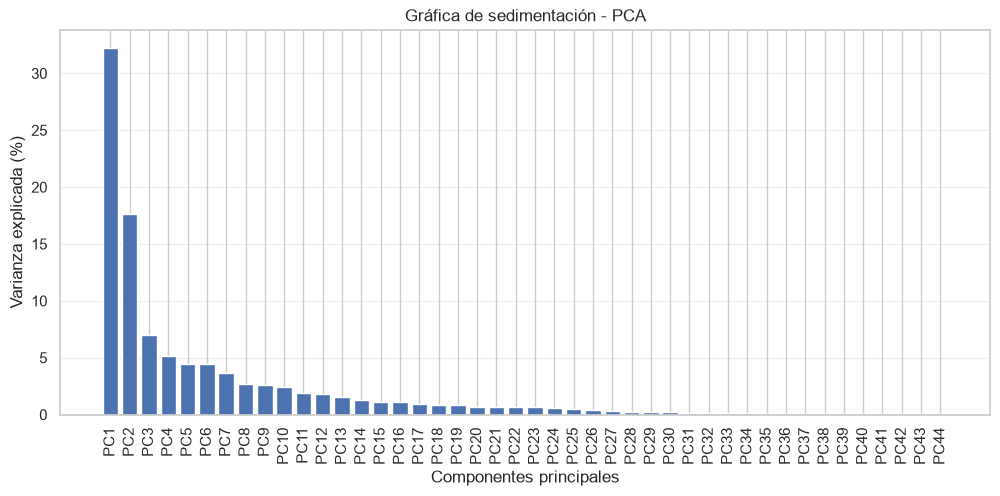

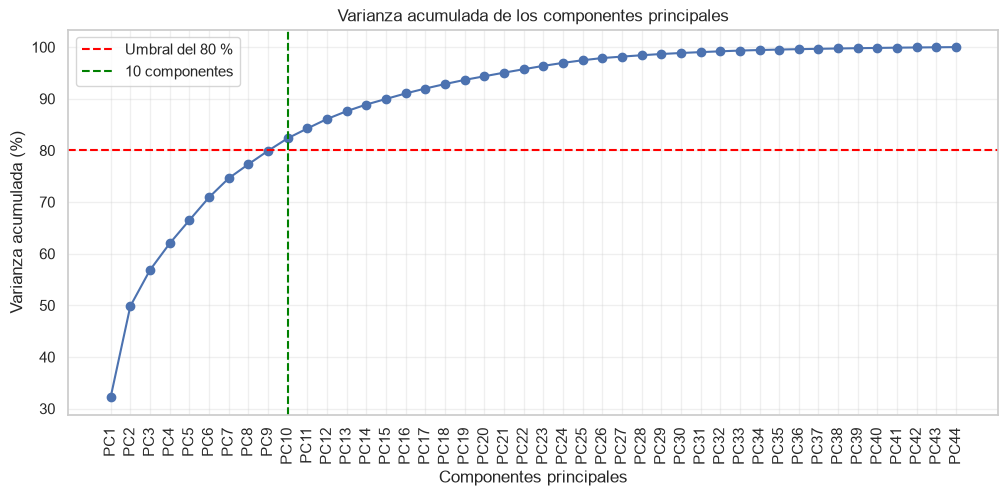

In [8]:
# ==========================================
# 8. VISUALIZACIÓN DE LA VARIANZA EXPLICADA
# ==========================================

componentes_nombres = [
    f"PC{i+1}" for i in range(len(varianza_explicada))
]

# Gráfica 1: Varianza explicada individual
plt.figure(figsize=(12, 5))

plt.bar(componentes_nombres, varianza_explicada * 100)

plt.title("Gráfica de sedimentación - PCA")
plt.xlabel("Componentes principales")
plt.ylabel("Varianza explicada (%)")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.show()


# Gráfica 2: Varianza acumulada
plt.figure(figsize=(12, 5))

plt.plot(
    componentes_nombres,
    varianza_acumulada * 100,
    marker="o"
)

plt.axhline(
    y=80,
    color="red",
    linestyle="--",
    label="Umbral del 80 %"
)

plt.axvline(
    x=9,
    color="green",
    linestyle="--",
    label="10 componentes"
)

plt.title("Varianza acumulada de los componentes principales")
plt.xlabel("Componentes principales")
plt.ylabel("Varianza acumulada (%)")
plt.xticks(rotation=90)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

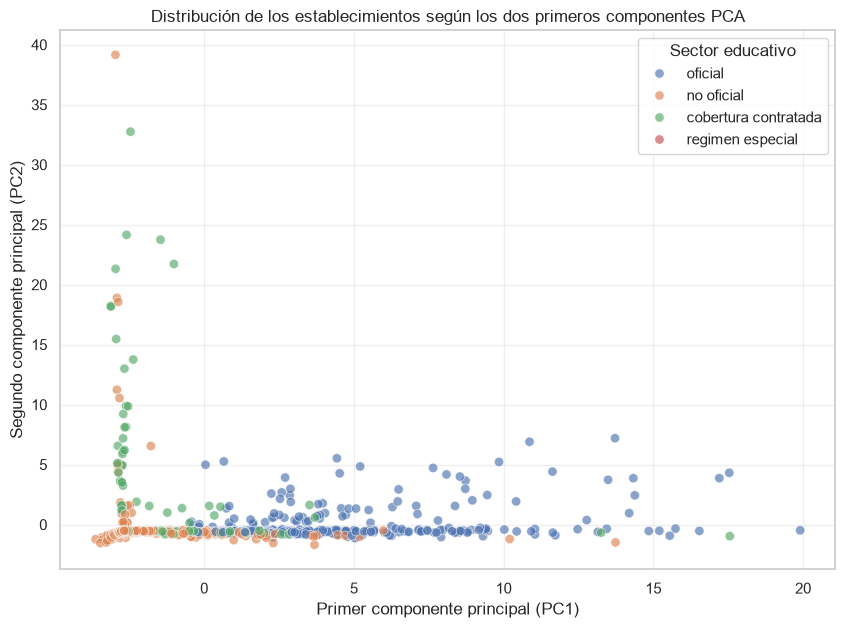

Varianza representada en esta gráfica: 49.84 %


In [9]:
# ==========================================
# 9. VISUALIZACIÓN DE LOS DOS PRIMEROS COMPONENTES
# ==========================================

# Crear un DataFrame con los dos primeros componentes
df_componentes = pd.DataFrame({
    "PC1": componentes[:, 0],
    "PC2": componentes[:, 1],
    "Sector": df["sector"].values,
    "Sexo": df["sexo"].values
})

# Gráfica de dispersión
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_componentes,
    x="PC1",
    y="PC2",
    hue="Sector",
    alpha=0.65,
    s=45
)

plt.title("Distribución de los establecimientos según los dos primeros componentes PCA")
plt.xlabel("Primer componente principal (PC1)")
plt.ylabel("Segundo componente principal (PC2)")
plt.legend(title="Sector educativo")
plt.grid(alpha=0.3)

plt.show()

print("Varianza representada en esta gráfica:",
      round(varianza_acumulada[1] * 100, 2), "%")

In [10]:
# ==========================================
# 10. INTERPRETACIÓN DE LOS COMPONENTES
# ==========================================

# Obtener los pesos de cada variable en los componentes
cargas_pca = pd.DataFrame(
    pca.components_.T,
    index=df_pca_limpio.columns,
    columns=[
        f"PC{i+1}" for i in range(len(pca.components_))
    ]
)

# Variables con mayor influencia en PC1
print("VARIABLES CON MAYOR INFLUENCIA EN PC1")

display(
    cargas_pca["PC1"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Peso absoluto")
)

# Variables con mayor influencia en PC2
print("VARIABLES CON MAYOR INFLUENCIA EN PC2")

display(
    cargas_pca["PC2"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Peso absoluto")
)

VARIABLES CON MAYOR INFLUENCIA EN PC1


,Peso absoluto
matricula_grado_5,0.244336
matricula_grado_4,0.243217
matricula_grado_6,0.242813
matricula_grado_3,0.242658
matricula_grado_2,0.239780
matricula_grado_1,0.239636
matricula_grado_7,0.236873
matricula_grado_8,0.227760
matricula_grado_transicion,0.227334
matricula_grado_9,0.217924


VARIABLES CON MAYOR INFLUENCIA EN PC2


,Peso absoluto
matricula_grado_clei4,0.338083
matricula_grado_clei3,0.337639
desercion_grado_clei4,0.336296
matricula_grado_clei6,0.327431
desercion_grado_clei5,0.326376
desercion_grado_clei6,0.324969
matricula_grado_clei5,0.319291
desercion_grado_clei3,0.303275
matricula_grado_clei2,0.255295
desercion_grado_clei2,0.252320


In [11]:
# ==========================================
# 11. CONSTRUCCIÓN DEL DATASET REDUCIDO
# ==========================================

# Aplicar PCA conservando 10 componentes
pca_reducido = PCA(n_components=10)

datos_reducidos = pca_reducido.fit_transform(datos_estandarizados)

# Crear DataFrame con los componentes
columnas_componentes = [
    f"PC{i+1}" for i in range(10)
]

df_reducido = pd.DataFrame(
    datos_reducidos,
    columns=columnas_componentes
)

# Incorporar variables descriptivas originales
df_reducido["establecimiento_educativo"] = df["establecimiento_educativo"].values
df_reducido["sector"] = df["sector"].values
df_reducido["sexo"] = df["sexo"].values

print("DIMENSIONES DEL DATASET ORIGINAL:")
print(df_pca_limpio.shape)

print("\nDIMENSIONES DEL DATASET REDUCIDO:")
print(df_reducido.shape)

print("\nVARIANZA EXPLICADA POR LOS 10 COMPONENTES:")
print(round(pca_reducido.explained_variance_ratio_.sum() * 100, 2), "%")

print("\nVISTA DEL DATASET REDUCIDO:")
display(df_reducido.head())

DIMENSIONES DEL DATASET ORIGINAL:
(1134, 44)

DIMENSIONES DEL DATASET REDUCIDO:
(1134, 13)

VARIANZA EXPLICADA POR LOS 10 COMPONENTES:
82.34 %

VISTA DEL DATASET REDUCIDO:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,establecimiento_educativo,sector,sexo
0,0.813321,-0.642473,1.176636,-0.349673,0.218053,-0.058293,-1.328144,0.300405,-0.408910,-0.119854,inst educ jose maria velaz,oficial,hombres
1,0.998689,-0.622462,0.949098,-0.470450,0.069863,-0.128570,-0.954974,0.214093,-0.391936,0.052145,inst educ jose maria velaz,oficial,mujeres
2,4.431614,5.524733,-2.679664,-0.563853,1.503426,1.648288,0.546230,-0.313332,0.208674,3.712753,inst educ barrio santa cruz,oficial,hombres
3,4.524713,4.265113,-1.506917,0.572642,11.355756,8.597839,3.562134,-0.567526,-0.200581,-3.649828,inst educ barrio santa cruz,oficial,mujeres
4,-3.078132,-1.227782,-2.671753,8.020073,-0.153503,-0.218711,-0.750092,-0.031959,1.065228,-0.069724,col comfama - sede aranjuez,no oficial,hombres


COMPARACIÓN DE DIMENSIONALIDAD
--------------------------------
Variables originales: 44
Componentes conservados: 10
Porcentaje de reducción: 77.27 %
Varianza conservada: 82.34 %


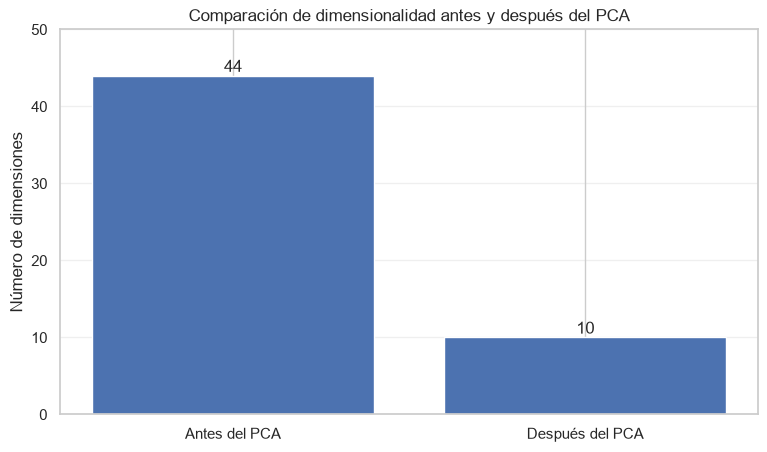

In [12]:
# ==========================================
# 12. COMPARACIÓN ANTES Y DESPUÉS DEL PCA
# ==========================================

variables_originales = df_pca_limpio.shape[1]
componentes_conservados = len(columnas_componentes)

reduccion = (
    (variables_originales - componentes_conservados)
    / variables_originales
) * 100

print("COMPARACIÓN DE DIMENSIONALIDAD")
print("--------------------------------")
print("Variables originales:", variables_originales)
print("Componentes conservados:", componentes_conservados)
print("Porcentaje de reducción:", round(reduccion, 2), "%")
print("Varianza conservada:",
      round(pca_reducido.explained_variance_ratio_.sum() * 100, 2), "%")

# Gráfica comparativa
plt.figure(figsize=(9, 5))

categorias = ["Antes del PCA", "Después del PCA"]
cantidades = [variables_originales, componentes_conservados]

barras = plt.bar(categorias, cantidades)

plt.title("Comparación de dimensionalidad antes y después del PCA")
plt.ylabel("Número de dimensiones")

for barra, cantidad in zip(barras, cantidades):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.5,
        str(cantidad),
        ha="center"
    )

plt.ylim(0, 50)
plt.grid(axis="y", alpha=0.3)
plt.show()

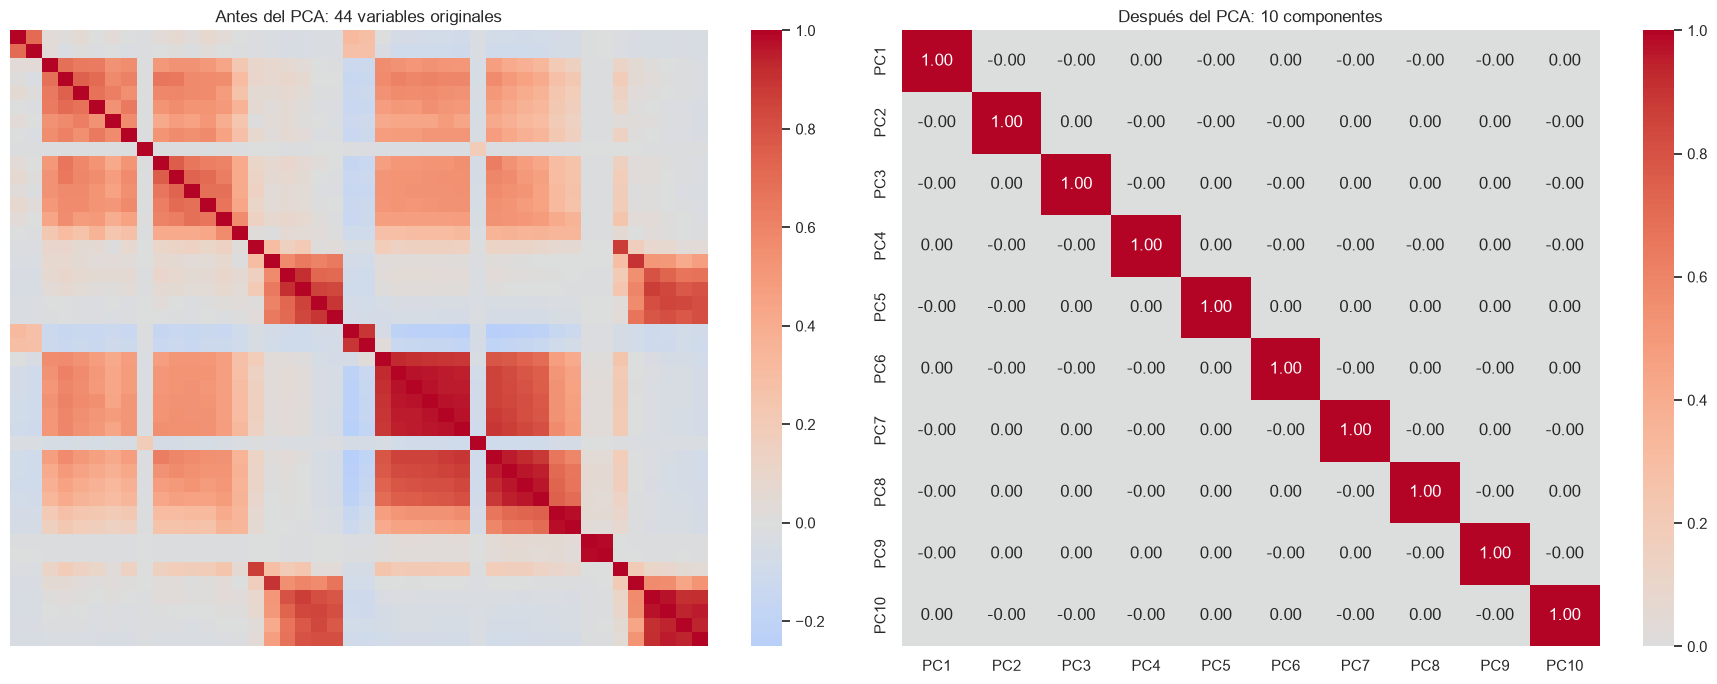

In [13]:
# ==========================================
# 13. COMPARACIÓN DE CORRELACIONES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Correlación de las variables originales
correlacion_original = df_pca_limpio.corr()

sns.heatmap(
    correlacion_original,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False,
    ax=axes[0]
)

axes[0].set_title("Antes del PCA: 44 variables originales")

# Correlación de los componentes principales
correlacion_reducida = df_reducido[columnas_componentes].corr()

sns.heatmap(
    correlacion_reducida,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    ax=axes[1]
)

axes[1].set_title("Después del PCA: 10 componentes")

plt.tight_layout()
plt.show()